# 1e — Calibrage (risk quantification) · Segment : Comptes joints

Chapitre 8 du cours : associer à chaque **Classe Homogène de Risque** (CHR, notebook `1d`) une **probabilité de
défaut** $PD_k = P(Y = 1 \mid CHR = k)$, puis la rendre prudente par une **Margin of Conservatism** (MoC). Le calibrage ne
modifie ni les variables, ni les coefficients, ni les bornes des CHR.

| Étape | Question | Section |
|-------|----------|---------|
| 8.1 | En quoi quantifier le risque diffère-t-il de le discriminer ? | Discrimination / quantification |
| 8.2 | Pourquoi le taux observé ne suffit-il pas ? | Fréquence observée, IC de Wald et de Wilson |
| 8.3 | PIT ou TTC ? Comment les relier ? | PD par cohorte, absence de croisement, modèle ASRF |
| 8.4 | Comment estimer une PD TTC ? | Long Run Average |
| 8.5 | Quelles autres méthodes ? | Logistique sur le score, isotone, crédibilité |
| 8.6 | Les PD reflètent-elles le risque observé ? | Diagramme de calibration, Brier et Murphy, Hosmer-Lemeshow |
| 8.7 | Comment passer à une PD réglementaire ? | MoC A / B / C, plancher |

> Les PD sont estimées sur l'**apprentissage** et vérifiées sur le **test** ; l'OOT (base fournie plus tard) sera notée
> avec la table de correspondance score → CHR → PD exportée en fin de notebook, sans rien réestimer.

## 0. Imports et configuration

In [1]:
import sys, json
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from utils.modele import appliquer_fusions
from utils.scorecard import noter
from utils.chr import affecter_chr, libelles_chr, table_chr, chr_optbinning, perte_information
from utils.calibrage import (
    table_frequence, taux_cohortes, croisements, rho_bale_retail, pd_pit, estimer_z, pd_lra,
    calibrer_logistique, calibrer_isotone, pd_credibilite, pd_moyenne_par_chr,
    table_verification, synthese_calibrage, hosmer_lemeshow, table_moc, pd_choc_conjoncture,
    plot_taux_cohortes, plot_diagramme_calibration, plot_pd_reglementaire, echelle_maitre, affecter_grade,
)
from utils.exploration import exporter_excel

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(16)
pl.Config.set_tbl_width_chars(200)

polars.config.Config

### Paramètres

| Paramètre | Valeur | Justification |
|-----------|--------|---------------|
| `CHOIX_CHR` | `"export_1d"` | bornes des CHR retenues en `1d` (optbinning à 4 classes : 600 · 629 · 676 points) |
| `ALPHA` | 5 % | niveau des IC (Wilson) et des tests |
| `RHO` | 0,04 | corrélation d'actif bâloise des expositions renouvelables de détail (découverts de comptes courants) ; la formule « autre clientèle de détail » (0,03 – 0,16) est montrée pour comparaison |
| `DELTA_Z` | 0,5 | MoC B : conjoncture non couverte par l'historique, en écarts-types du facteur systémique (voir 8.7) |
| `MOC_C` | 5 % de la PD | MoC C : jugement expert, plafonné |
| `PLANCHER` | 0,05 % | PD minimale réglementaire de la clientèle de détail (CRR3, art. 160 et 163) |

In [2]:
VERSION = "_v2"     # "" : modèle de référence ; "_v2" : variante retenue (1b_v2 / 1c_v2 / 1d_v2)

BASE_CL    = ROOT / "data/segments/joint/base_joint_classes.parquet"   # variables en classes (sortie de 1a)
GRILLE     = ROOT / f"outputs/scorecard/grille_joint{VERSION}.json"
CHR_1D     = ROOT / f"outputs/chr/chr_joint{VERSION}.json"
SORTIE     = ROOT / f"outputs/calibrage/calibrage_joint{VERSION}.json"
SORTIE_XLS = ROOT / f"outputs/calibrage/calibrage_joint{VERSION}.xlsx"

TARGET   = "ddefaut_ndb"
DATE_COL = "datdelhis"
COHORTE  = "1mo"              # cohortes mensuelles, comme aux ch. 4 et 7

CHOIX_CHR = "export_1d"       # "export_1d" : bornes retenues en 1d (chr_joint*.json) ; "optbinning_4" : recalcul
ALPHA     = 0.05
RHO       = 0.04              # QRRE (CRR art. 154) ; alternative : rho_bale_retail(PD)
DELTA_Z   = 0.5               # MoC B : écart de conjoncture non couvert (écarts-types de Z)
MOC_C     = 0.05              # MoC C : 5 % de la PD calibrée
PLANCHER  = 0.0005            # plancher de PD retail (0,05 %)

## 1. Chargement : score en points et CHR de chaque dossier

In [3]:
g = json.loads(GRILLE.read_text(encoding="utf-8"))
FUSIONS = {v: {int(a): b for a, b in f.items()} for v, f in g["fusions"].items()}
grille = pl.DataFrame(g["grille_pdo"])

df = appliquer_fusions(pl.read_parquet(BASE_CL), FUSIONS)
df = noter(df, grille, "points").with_columns(cohorte=pl.col(DATE_COL).dt.truncate(COHORTE).dt.to_string("%Y-%m"))
df_app = df.filter(pl.col("echantillon") == "apprentissage")

if CHOIX_CHR == "export_1d":
    BORNES = json.loads(CHR_1D.read_text(encoding="utf-8"))["bornes_points"]
elif CHOIX_CHR == "optbinning_4":
    BORNES = chr_optbinning(df_app["points"], df_app[TARGET], min_bin_size=0.02, min_bin_n_event=5, max_n_bins=4)
else:
    raise ValueError(CHOIX_CHR)
LIBELLES = libelles_chr(BORNES)
K = len(BORNES) + 1

df = df.with_columns(CHR=pl.Series(affecter_chr(df["points"], BORNES)))
df_app  = df.filter(pl.col("echantillon") == "apprentissage")
df_test = df.filter(pl.col("echantillon") == "test")
print(f"Grille {GRILLE.name} | découpage {CHOIX_CHR} : {K} CHR, bornes {BORNES}")
print(f"apprentissage : {df_app.height} dossiers, {int(df_app[TARGET].sum())} défauts | "
      f"test : {df_test.height} dossiers, {int(df_test[TARGET].sum())} défauts")

tab_app = table_chr(df_app, "CHR", TARGET, 0.30, ALPHA, points="points")
ordonne = bool((tab_app["taux_defaut"].diff().drop_nulls() > 0).all())
print("Taux de défaut strictement croissants avec la CHR (apprentissage) :", ordonne)
if not ordonne:
    print("ATTENTION : CHR non ordonnées, le calibrage produirait des PD non monotones — revoir le découpage (1d).")
tab_app.with_columns(libelle=pl.col("CHR").replace_strict(LIBELLES)).select(
    "CHR", "libelle", "n", "part", "n_defaut", "taux_defaut", "R", "R_ic_bas")

Grille grille_joint_v2.json | découpage export_1d : 4 CHR, bornes [600.0, 629.0, 676.0]
apprentissage : 47156 dossiers, 228 défauts | test : 11791 dossiers, 56 défauts


Taux de défaut strictement croissants avec la CHR (apprentissage) : True


CHR,libelle,n,part,n_defaut,taux_defaut,R,R_ic_bas
i64,str,u32,f64,f64,f64,f64,f64
1,"""> 676""",27796,0.589448,8.0,0.000288,null,null
2,"""]629 ; 676]""",13112,0.278056,32.0,0.002441,7.479561,0.912434
3,"""]600 ; 629]""",3545,0.075176,46.0,0.012976,4.316925,1.926206
4,"""≤ 600""",2703,0.05732,142.0,0.052534,3.048561,1.717713


## 8.1 De la discrimination à la quantification du risque

Les chapitres 5 à 7 ont produit un **ordre** : la CHR 4 est plus risquée que la CHR 3, etc. Les métriques utilisées
(AUC, Gini, KS) ne regardent que cet ordre : multiplier toutes les PD par 10 ne changerait pas le Gini (scénario C du
cours). Le calibrage cherche à présent la **valeur absolue** du risque de chaque CHR, et se juge avec d'autres outils
(8.6).

Pour rappel, le pouvoir discriminant du système de notation, que le calibrage ne modifie pas :

In [4]:
pl.concat([perte_information(d[TARGET], d["points"], d["CHR"], nom) for d, nom in
           ((df_app, "apprentissage"), (df_test, "test"))]).select("modele", "n_defaut", "gini", "gini_ic_bas",
                                                                   "gini_ic_haut", "ks", "delta_gini")

modele,n_defaut,gini,gini_ic_bas,gini_ic_haut,ks,delta_gini
str,i64,f64,f64,f64,f64,f64
"""score en points — apprentissag…",228,0.83163,0.781772,0.881489,0.695427,0.0
"""CHR — apprentissage""",228,0.804182,0.751024,0.85734,0.695427,0.027449
"""score en points — test""",56,0.796199,0.687139,0.905259,0.672444,0.0
"""CHR — test""",56,0.766361,0.651069,0.881654,0.635433,0.029837


## 8.2 Pourquoi une fréquence observée ne suffit pas

PD naïve : $PD_k^{naïf} = n_{1,k} / n_k$ sur l'apprentissage. Sa précision dépend du **nombre de défauts** $n_{1,k}$, pas
de l'effectif. Deux intervalles à 95 % :

- **Wald** : $\hat p \pm z \sqrt{\hat p (1 - \hat p)/n}$, variance évaluée au point estimé, peut devenir négatif à PD faible ;
- **Wilson** : inversion correcte du test en $p$, toujours dans $[0, 1]$ et de couverture proche de 95 % même quand
  $\hat p$ est proche de 0, le régime de ce portefeuille.

In [5]:
freq_app = table_frequence(df_app, "CHR", TARGET, ALPHA)
freq_app.with_columns(largeur_rel_wilson=(pl.col("wilson_haut") - pl.col("wilson_bas")) / pl.col("pd_naive"))

CHR,n,n_defaut,part,pd_naive,wald_bas,wald_haut,wilson_bas,wilson_haut,largeur_rel_wilson
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64
1,27796,8.0,0.589448,0.000288,0.000088,0.000487,0.000146,0.000568,1.466341
2,13112,32.0,0.278056,0.002441,0.001596,0.003285,0.001729,0.003443,0.702234
3,3545,46.0,0.075176,0.012976,0.009251,0.016701,0.009743,0.017264,0.579613
4,2703,142.0,0.05732,0.052534,0.044124,0.060945,0.044741,0.061598,0.320881


**Lecture** : la précision suit le **nombre de défauts**, pas l'effectif.

- **CHR 1** : 27 796 dossiers mais **8 défauts** → PD naïve 0,029 %, IC de Wilson [0,015 % ; 0,057 %] : l'intervalle est
  plus large que la PD elle-même (147 % de la PD). Wald donne [0,009 % ; 0,049 %], **symétrique**, alors que l'incertitude
  réelle est surtout vers le haut : Wilson est plus prudent du côté qui compte.
- **CHR 4** : 2 703 dossiers seulement mais 142 défauts → 5,25 % [4,47 % ; 6,16 %], largeur relative 32 %.
- C'est l'incertitude que couvrira la MoC A (8.7) : elle sera forte en CHR 1 et faible en CHR 4.

## 8.3 Les différentes notions de PD : PIT et TTC

### 8.3.1 PD Point-in-Time par cohorte et absence de croisement

Taux de défaut observé de chaque CHR dans chaque cohorte mensuelle de l'apprentissage. Toutes les CHR peuvent monter ou
baisser ensemble avec la conjoncture, mais leurs trajectoires **ne doivent pas se croiser**.

In [6]:
tl_app = taux_cohortes(df_app, "CHR", TARGET, "cohorte")
display(tl_app.pivot(on="cohorte", index="CHR", values="taux").sort("CHR"))
display(tl_app.pivot(on="cohorte", index="CHR", values="n_defaut").sort("CHR"))
croisements(tl_app, "cohorte")

CHR,2021-01,2021-02,2021-03,2021-04
i64,f64,f64,f64,f64
1,0.00029,0.00029,0.0,0.000572
2,0.003947,0.003018,0.000612,0.002164
3,0.011338,0.011211,0.015837,0.013529
4,0.052147,0.042213,0.051051,0.06447


CHR,2021-01,2021-02,2021-03,2021-04
i64,f64,f64,f64,f64
1,2.0,2.0,0.0,4.0
2,13.0,10.0,2.0,7.0
3,10.0,10.0,14.0,12.0
4,34.0,29.0,34.0,45.0


cohorte,n_inversions,n_defaut,ordre_respecte
str,u32,f64,bool
"""2021-01""",0,59.0,true
"""2021-02""",0,51.0,true
"""2021-03""",0,50.0,true
"""2021-04""",0,68.0,true


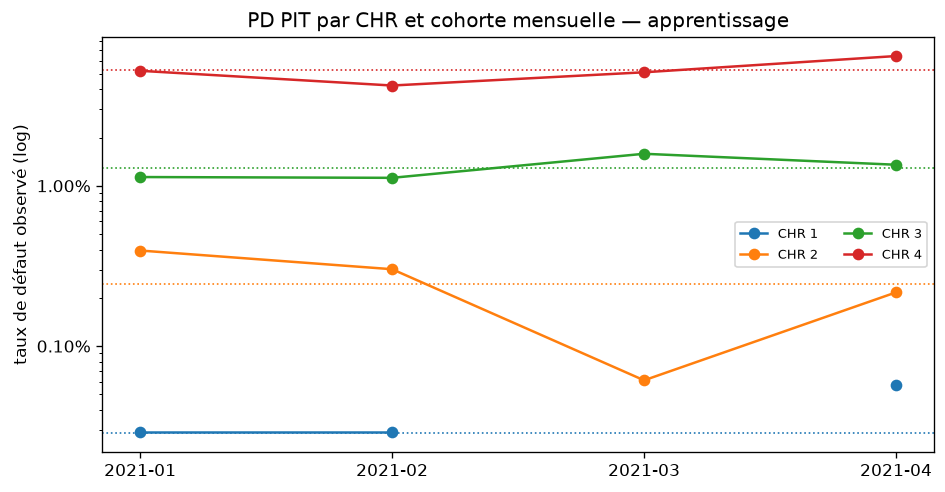

In [7]:
lra = pd_lra(tl_app)
PD_LRA = dict(zip(lra["CHR"], lra["pd_lra"]))
fig = plot_taux_cohortes(tl_app, "cohorte", PD_LRA, titre="PD PIT par CHR et cohorte mensuelle — apprentissage")
plt.show()

**Lecture** :

- **Aucun croisement** : l'ordre CHR 1 < CHR 2 < CHR 3 < CHR 4 est respecté dans les **4 cohortes** mensuelles, y compris
  en mars où la CHR 1 n'a aucun défaut.
- Les taux mensuels fluctuent beaucoup dans les petites CHR (CHR 2 : de 0,06 % à 0,39 %, soit 2 à 13 défauts par mois),
  bien moins en CHR 4 (4,2 % à 6,4 %). Avril est un peu plus élevé dans 3 CHR sur 4 (68 défauts contre 50 à 59) : un
  mouvement commun qui peut relever de la conjoncture, mais sur 4 mois il ne se distingue pas du bruit binomial.

### 8.3.3 Relier PIT et TTC : le modèle à un facteur (Vasicek / ASRF)

$PD_k^{PIT}(Z) = \Phi\left(\dfrac{\Phi^{-1}(PD_k^{TTC}) - \sqrt{\rho}\, Z}{\sqrt{1 - \rho}}\right)$, $Z \sim \mathcal N(0, 1)$
le facteur systémique (Z < 0 : conjoncture dégradée). Le facteur $Z_t$ de chaque cohorte est estimé par maximum de
vraisemblance binomiale sur les K CHR à la fois (une inversion CHR par CHR est impossible quand une CHR n'a aucun
défaut dans le mois), en prenant la PD LRA (8.4) comme PD TTC.

Corrélation d'actif : $\rho = 0{,}04$ (expositions renouvelables de détail). La formule bâloise « autre clientèle de
détail », qui donnerait $\rho$ entre 0,03 et 0,16, est affichée pour comparaison.

In [8]:
lra.select("CHR", "pd_lra").with_columns(rho_qrre=pl.lit(RHO), rho_autre_retail=pl.Series(rho_bale_retail(lra["pd_lra"])))

CHR,pd_lra,rho_qrre,rho_autre_retail
i64,f64,f64,f64
1,0.000288,0.04,0.158697
2,0.002435,0.04,0.14938
3,0.012979,0.04,0.11254
4,0.05247,0.04,0.05072


In [9]:
z_coh = estimer_z(tl_app, PD_LRA, {k: RHO for k in PD_LRA}, "cohorte")
z_coh

cohorte,z,n_defaut,attendus_ttc
str,f64,i64,f64
"""2021-01""",-0.383982,59,55.664495
"""2021-02""",-0.020658,51,57.679436
"""2021-03""",0.121533,50,56.390348
"""2021-04""",-0.539728,68,58.027269


In [10]:
# Sensibilité au cycle : PD PIT de chaque CHR pour quelques états du facteur Z
grille_z = [-2.0, -1.0, 0.0, 1.0]
pl.DataFrame({"CHR": list(PD_LRA), "pd_ttc": list(PD_LRA.values()),
              **{f"pit_Z={z:+.0f}": pd_pit(list(PD_LRA.values()), RHO, z) for z in grille_z}})

CHR,pd_ttc,pit_Z=-2,pit_Z=-1,pit_Z=+0,pit_Z=+1
i64,f64,f64,f64,f64,f64
1,0.000288,0.000949,0.000467,0.000221,0.0001
2,0.002435,0.006844,0.003799,0.002029,0.001043
3,0.012979,0.031124,0.01929,0.01152,0.006627
4,0.05247,0.106282,0.073436,0.048983,0.031519


**Lecture** :

- Les $Z_t$ estimés (−0,38 ; −0,02 ; +0,12 ; −0,54) sont **centrés sur la période elle-même**, puisque la PD TTC de
  référence est la LRA de ces 4 mois : ils décrivent les fluctuations d'un mois à l'autre, pas la position de 2021 dans
  le cycle. Il faudrait plusieurs années d'historique pour dire si 2021 est une année favorable ou dégradée.
- **Sensibilité au cycle** : avec ρ = 0,04, une conjoncture à Z = −2 (récession sévère) multiplierait la PD de la CHR 1
  par 3,3 et celle de la CHR 4 par 2,0. En relatif, les classes peu risquées sont les plus sensibles. L'ordre des CHR est
  préservé pour tout Z, ce que l'ASRF démontre analytiquement.

## 8.4 Le calibrage Through-the-Cycle : Long Run Average

$PD_k^{LRA} = \frac{1}{T}\sum_{t=1}^{T} \tau_{k,t}$ : moyenne simple des taux des T cohortes, comparée au taux poolé
(toutes cohortes regroupées). La LRA n'est un estimateur de la PD TTC que si les cohortes couvrent un cycle
représentatif ; ce n'est pas le cas ici (4 mois d'une même année), d'où la MoC B (8.7).

In [11]:
lra.select("CHR", "n_cohortes", "n", "n_defaut", "pd_lra", "pd_poolee", "taux_min", "taux_max", "ecart_type") \
   .with_columns(ecart_lra_poolee=pl.col("pd_lra") / pl.col("pd_poolee") - 1)

CHR,n_cohortes,n,n_defaut,pd_lra,pd_poolee,taux_min,taux_max,ecart_type,ecart_lra_poolee
i64,u32,u32,f64,f64,f64,f64,f64,f64,f64
1,4,27796,8.0,0.000288,0.000288,0.0,0.000572,0.000233,-0.000167
2,4,13112,32.0,0.002435,0.002441,0.000612,0.003947,0.001417,-0.002288
3,4,3545,46.0,0.012979,0.012976,0.011211,0.015837,0.002183,0.0002
4,4,2703,142.0,0.05247,0.052534,0.042213,0.06447,0.009153,-0.001219


**Lecture** : LRA et taux poolé sont **identiques à 0,3 % près** : les 4 cohortes ont des effectifs quasi égaux, et la
moyenne simple se confond alors avec la moyenne pondérée. La LRA est retenue, comme le veut le cours, mais elle ne
garantit ici aucune vision TTC : T = 4 mois consécutifs d'une même année ne couvrent pas un cycle. Cette limite est
**documentée et couverte par la MoC B**.

## 8.5 Les méthodes de calibrage

Cinq jeux de PD par CHR, tous estimés sur l'apprentissage :

| Méthode | PD de la CHR k |
|---------|----------------|
| fréquence observée | taux poolé $n_{1,k}/n_k$ |
| **LRA** | moyenne des taux mensuels (8.4) |
| régression logistique | moyenne, sur la CHR, de $PD(s) = 1/(1+e^{-(a + b\,s)})$ ajustée sur le score en points |
| régression isotone | moyenne, sur la CHR, de la PD isotone (décroissante) du score |
| crédibilité | $w_k\, \hat p_k + (1 - w_k)\, \bar p$, $w_k = n_k/(n_k + m)$, a priori $\bar p$ = taux du portefeuille, de poids $m = 1/\bar p$ dossiers (l'équivalent d'**un** défaut) |

In [12]:
pts_app, y_app = df_app["points"].to_numpy(), df_app[TARGET].to_numpy()
f_logit, (a_logit, b_logit) = calibrer_logistique(pts_app, y_app)
f_iso = calibrer_isotone(pts_app, y_app)
p_bar = float(y_app.mean())
M_CRED = 1 / p_bar
pd_cred, w_cred = pd_credibilite(freq_app["n"], freq_app["n_defaut"], p_bar, M_CRED)

METHODES = {
    "fréquence observée": dict(zip(freq_app["CHR"], freq_app["pd_naive"])),
    "LRA": PD_LRA,
    "logistique sur le score": pd_moyenne_par_chr(df_app["CHR"], f_logit(pts_app)),
    "isotone": pd_moyenne_par_chr(df_app["CHR"], f_iso(pts_app)),
    "crédibilité": dict(zip(freq_app["CHR"], pd_cred)),
}
print(f"logistique : PD(s) = 1 / (1 + exp(-({a_logit:.3f} {b_logit:+.4f} s))) | crédibilité : m = {M_CRED:.0f} dossiers, "
      f"w = {', '.join(f'{w:.3f}' for w in w_cred)}")
tab_methodes = pl.DataFrame({"CHR": list(range(1, K + 1)), "score": [LIBELLES[k] for k in range(1, K + 1)],
                             **{m: [METHODES[m][k] for k in range(1, K + 1)] for m in METHODES}})
tab_methodes

logistique : PD(s) = 1 / (1 + exp(-(16.991 -0.0350 s))) | crédibilité : m = 207 dossiers, w = 0.993, 0.984, 0.945, 0.929


CHR,score,fréquence observée,LRA,logistique sur le score,isotone,crédibilité
i64,str,f64,f64,f64,f64,f64
1,"""> 676""",0.000288,0.000288,0.000437,0.000288,0.000321
2,"""]629 ; 676]""",0.002441,0.002435,0.002746,0.002441,0.002478
3,"""]600 ; 629]""",0.012976,0.012979,0.010455,0.012976,0.012527
4,"""≤ 600""",0.052534,0.05247,0.052822,0.052534,0.049144


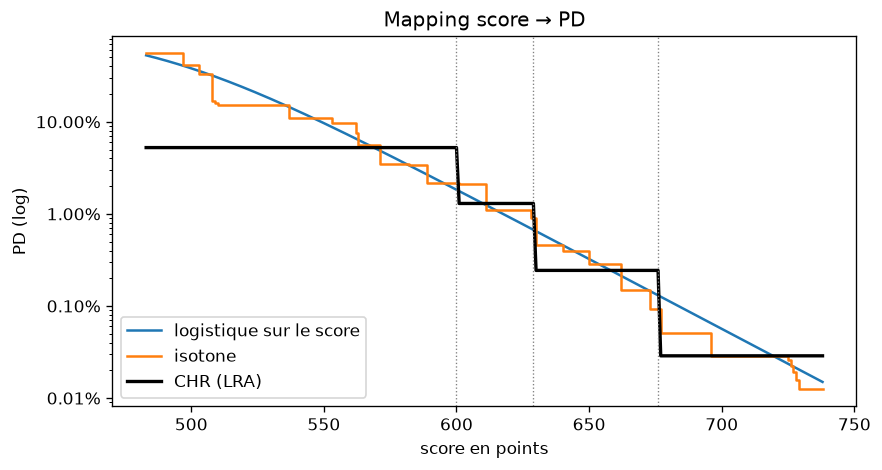

In [13]:
# Courbe score → PD des deux méthodes continues, et PD en escalier des CHR (LRA)
s = np.arange(df_app["points"].min(), df_app["points"].max() + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(s, f_logit(s), label="logistique sur le score")
ax.plot(s, f_iso(s), label="isotone", drawstyle="steps-post")
ax.plot(s, [PD_LRA[k] for k in affecter_chr(s, BORNES)], label="CHR (LRA)", lw=2, color="k")
ax.set_yscale("log"); ax.set_xlabel("score en points"); ax.set_ylabel("PD (log)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2%}"))
for b in BORNES:
    ax.axvline(b, color="grey", ls=":", lw=0.8)
ax.legend(); ax.set_title("Mapping score → PD")
plt.show()

**Lecture** :

- **Fréquence observée, LRA et isotone** donnent la même PD par CHR (à 0,3 % près). Ce n'est pas un hasard : la régression
  isotone conserve la moyenne des défauts sur chaque bloc monotone, et les CHR sont déjà monotones.
- **Logistique sur le score** : la forme logistique impose une pente unique (−0,035 par point, cohérente avec le PDO de
  la grille). Elle **surestime la CHR 1** (0,044 % contre 0,029 %, +52 %) et **sous-estime la CHR 3** (1,05 % contre
  1,30 %, −19 %) : le risque observé décroît plus vite que la logistique en haut du score. Elle reste utile pour une PD
  individuelle infra-CHR, ce qui n'est pas l'objectif ici.
- **Crédibilité** : avec un a priori équivalent à un défaut, les poids $w_k$ valent de 0,93 à 0,99 et les PD bougent peu
  (CHR 1 : 0,032 %, CHR 4 : 4,9 %). Elle tire la CHR 4 **vers le bas**, ce qui est l'inverse de la prudence voulue.

**Décision : LRA.** C'est la méthode standard du cours pour une PD TTC, elle est égale ici à la fréquence observée, et
l'incertitude des petites CHR est traitée explicitement par la MoC A plutôt que par un lissage à l'a priori arbitraire.

## 8.6 Vérifier le calibrage

Sur l'**apprentissage** (ajustement) puis sur le **test** (échantillon indépendant, le seul contrôle probant) :

- **diagramme de calibration** : PD prédite contre taux observé par CHR, avec l'IC de Wilson du taux observé ;
- **Brier Score** et **décomposition de Murphy** : Brier = incertitude − résolution + calibration ; seul le terme de
  calibration dépend du calibrage ;
- **Hosmer-Lemeshow** sur les K CHR (ddl = K, échantillon indépendant du calibrage ; à interpréter avec prudence) ;
- **test binomial** par CHR (backtesting 9.2) : $P(D \geq d \mid PD)$ petite = risque sous-estimé.

In [14]:
synth = pl.concat([synthese_calibrage(df_app, "CHR", TARGET, METHODES, "apprentissage"),
                   synthese_calibrage(df_test, "CHR", TARGET, METHODES, "test")])
synth.select("echantillon", "methode", "brier", "incertitude", "resolution", "calibration", "log_loss",
             "attendus", "observes", "hl", "hl_pvalue", "n_chr_hors_ic")

echantillon,methode,brier,incertitude,resolution,calibration,log_loss,attendus,observes,hl,hl_pvalue,n_chr_hors_ic
str,str,f64,f64,f64,f64,f64,f64,i64,f64,f64,i64
"""apprentissage""","""fréquence observée""",0.004662,0.004812,0.000149,0.0,0.023323,228.0,228,0.0,1.0,0
"""apprentissage""","""LRA""",0.004662,0.004812,0.000149,2.4426e-10,0.023323,227.761548,228,0.000393,1.0,0
"""apprentissage""","""logistique sur le score""",0.004663,0.004812,0.000149,5.2173e-7,0.023366,228.003007,228,4.051637,0.399063,0
"""apprentissage""","""isotone""",0.004662,0.004812,0.000149,2.0952e-33,0.023323,228.0,228,6.3878e-26,1.0,0
"""apprentissage""","""crédibilité""",0.004663,0.004812,0.000149,6.7506e-7,0.023332,218.665982,228,0.827533,0.934719,0
"""test""","""fréquence observée""",0.004592,0.004727,0.000137,0.000002,0.023705,57.959665,56,2.32208,0.676752,0
"""test""","""LRA""",0.004592,0.004727,0.000137,0.000002,0.023706,57.899355,56,2.331521,0.675036,0
"""test""","""logistique sur le score""",0.004591,0.004727,0.000137,5.1134e-7,0.023624,57.903679,56,0.436128,0.979414,0
"""test""","""isotone""",0.004592,0.004727,0.000137,0.000002,0.023705,57.959665,56,2.32208,0.676752,0


CHR,n,n_defaut,attendus,pd_predite,taux_observe,obs_wilson_bas,obs_wilson_haut,pd_dans_ic,pvalue_sous_estimation,pvalue_bilaterale
i64,u32,f64,f64,f64,f64,f64,f64,bool,f64,f64
1,6957,3.0,2.001968,0.000288,0.000431,0.000147,0.001267,true,0.323856,0.458887
2,3237,10.0,7.881862,0.002435,0.003089,0.001679,0.005678,true,0.268663,0.470626
3,906,8.0,11.758631,0.012979,0.00883,0.004481,0.017327,true,0.900903,0.375064
4,691,35.0,36.256895,0.05247,0.050651,0.036643,0.069628,true,0.608842,0.931931


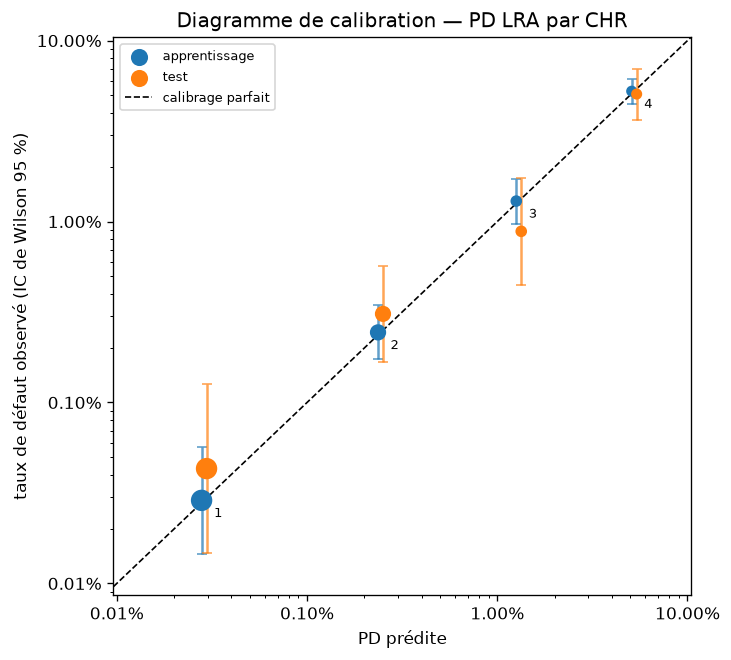

In [15]:
verif_test = table_verification(df_test, "CHR", TARGET, PD_LRA, ALPHA)
verif_app  = table_verification(df_app, "CHR", TARGET, PD_LRA, ALPHA)
display(verif_test.select("CHR", "n", "n_defaut", "attendus", "pd_predite", "taux_observe", "obs_wilson_bas",
                          "obs_wilson_haut", "pd_dans_ic", "pvalue_sous_estimation", "pvalue_bilaterale"))
fig = plot_diagramme_calibration({"apprentissage": verif_app, "test": verif_test},
                                 titre="Diagramme de calibration — PD LRA par CHR")
plt.show()

In [16]:
# Stabilité du calibrage dans le temps : défauts observés contre attendus (PD LRA), par cohorte du test
tl_test = taux_cohortes(df_test, "CHR", TARGET, "cohorte").with_columns(
    attendus=pl.col("n") * pl.col("CHR").replace_strict(PD_LRA, return_dtype=pl.Float64))
tl_test.group_by("cohorte").agg(n=pl.col("n").sum(), observes=pl.col("n_defaut").sum(),
                                attendus=pl.col("attendus").sum()).sort("cohorte") \
       .with_columns(ratio_obs_att=pl.col("observes") / pl.col("attendus"))

cohorte,n,observes,attendus,ratio_obs_att
str,u32,f64,f64,f64
"""2021-01""",2938,12.0,14.827715,0.809295
"""2021-02""",2943,14.0,14.803122,0.945746
"""2021-03""",2892,17.0,14.729589,1.154139
"""2021-04""",3018,13.0,13.538929,0.960194


**Lecture** :

- **Test, PD LRA** : 57,9 défauts attendus contre **56 observés**. Les 4 PD sont dans l'IC de Wilson du taux observé.
  Le test binomial ne détecte aucune sous-estimation (p ≥ 0,27), et Hosmer-Lemeshow vaut 2,3 pour 4 ddl
  (**p = 0,68**) : l'hypothèse de bon calibrage n'est pas rejetée. Le point le plus éloigné est la CHR 3 (8 défauts
  observés pour 11,8 attendus, 0,88 % contre 1,30 %), ce qui reste dans l'IC.
- **Murphy (test)** : Brier = 0,00459 = incertitude 0,00473 − résolution 0,000137 + calibration 0,000002. Le terme de
  calibration ne représente que **0,04 % du Brier** : il n'y a rien à corriger côté calibrage. Le Brier est dominé par
  l'incertitude, qui vient du faible taux de défaut du portefeuille (0,47 %) : c'est hors du contrôle du modèle.
- **Par cohorte du test**, le ratio observés / attendus va de 0,81 à 1,15, sans tendance.
- Les cinq méthodes ont des performances indiscernables sur le test : avec 56 défauts, le test ne peut pas les
  départager. Cela conforte le choix de la plus simple et de la plus standard.

## 8.7 Du calibrage à la PD réglementaire

$PD^{reg} = PD^{LRA} + MoC_A + MoC_B + MoC_C$ (somme, pratique la plus courante), puis plancher réglementaire.

| Catégorie | Incertitude couverte | Quantification retenue |
|-----------|----------------------|------------------------|
| **A** statistique | échantillon fini, peu de défauts par CHR | borne haute de l'IC de Wilson 95 % du taux poolé, moins ce taux |
| **B** limites connues | historique de 4 mois d'une seule année : cycle non couvert ; année probablement favorable | PD si la conjoncture était plus dégradée de Δ = 0,5 écart-type de Z (ASRF, ρ = 0,04), moins la PD |
| **C** jugement expert | évolutions futures du portefeuille, OOT non encore disponible | 5 % de la PD |

Le **plancher** de 0,05 % (CRR3) n'est pas une MoC : il s'applique à la PD finale.

In [17]:
moc = table_moc(lra["n"], lra["n_defaut"], lra["pd_lra"], RHO, alpha_a=ALPHA, delta_z=DELTA_Z,
                moc_c_relative=MOC_C, plancher=PLANCHER)
moc.with_columns(majoration_rel=pl.col("pd_finale") / pl.col("pd_calibree") - 1)

CHR,pd_calibree,moc_a,moc_b,moc_c,moc_totale,pd_reglementaire,pd_finale,plancher_actif,majoration_rel
i64,f64,f64,f64,f64,f64,f64,f64,bool,f64
1,0.000288,0.00028,0.00013,0.000014,0.000424,0.000712,0.000712,false,1.474585
2,0.002435,0.001003,0.000894,0.000122,0.002019,0.004454,0.004454,false,0.829066
3,0.012979,0.004288,0.003823,0.000649,0.00876,0.021739,0.021739,false,0.674967
4,0.05247,0.009064,0.011874,0.002624,0.023561,0.076031,0.076031,false,0.44903


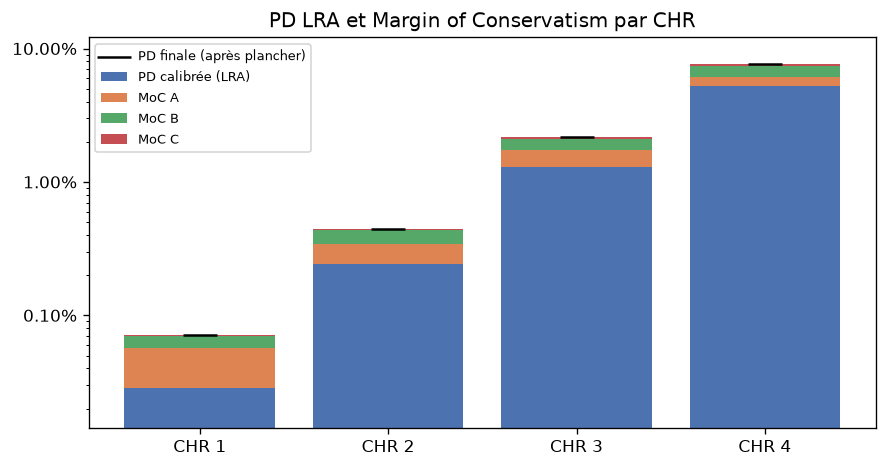

In [18]:
fig = plot_pd_reglementaire(moc, titre="PD LRA et Margin of Conservatism par CHR")
plt.show()

In [19]:
# Sensibilité de la PD finale aux deux paramètres à dire d'expert (MoC B)
sens = []
for rho in (0.04, 0.10, 0.15):
    for dz in (0.0, 0.5, 1.0):
        m = table_moc(lra["n"], lra["n_defaut"], lra["pd_lra"], rho, alpha_a=ALPHA, delta_z=dz,
                      moc_c_relative=MOC_C, plancher=PLANCHER)
        sens.append({"rho": rho, "delta_z": dz, **{f"PD finale CHR {k}": v for k, v in zip(m["CHR"], m["pd_finale"])}})
pl.DataFrame(sens)

rho,delta_z,PD finale CHR 1,PD finale CHR 2,PD finale CHR 3,PD finale CHR 4
f64,f64,f64,f64,f64,f64
0.04,0.0,0.000582,0.003559,0.017915,0.064157
0.04,0.5,0.000712,0.004454,0.021739,0.076031
0.04,1.0,0.000895,0.005633,0.026487,0.089894
0.1,0.0,0.000582,0.003559,0.017915,0.064157
0.1,0.5,0.00082,0.005163,0.024627,0.084564
0.1,1.0,0.001231,0.007653,0.034081,0.110555
0.15,0.0,0.000582,0.003559,0.017915,0.064157
0.15,0.5,0.000907,0.005712,0.026794,0.090763
0.15,1.0,0.001547,0.009425,0.040336,0.126509


In [20]:
# Contrôle : la PD finale couvre-t-elle les défauts du test ? (une PD prudente doit donner attendus ≥ observés)
PD_FINALE = dict(zip(moc["CHR"], moc["pd_finale"]))
verif_reg = table_verification(df_test, "CHR", TARGET, PD_FINALE, ALPHA)
display(verif_reg.select("CHR", "n", "n_defaut", "attendus", "pd_predite", "taux_observe", "pvalue_sous_estimation"))
print(f"test : {int(verif_reg['n_defaut'].sum())} défauts observés, {verif_reg['attendus'].sum():.1f} attendus avec la PD finale "
      f"({verif_test['attendus'].sum():.1f} avec la PD LRA)")

CHR,n,n_defaut,attendus,pd_predite,taux_observe,pvalue_sous_estimation
i64,u32,f64,f64,f64,f64,f64
1,6957,3.0,4.95404,0.000712,0.000431,0.871514
2,3237,10.0,14.416447,0.004454,0.003089,0.909388
3,906,8.0,19.695321,0.021739,0.00883,0.99913
4,691,35.0,52.537317,0.076031,0.050651,0.996811


test : 56 défauts observés, 91.6 attendus avec la PD finale (57.9 avec la PD LRA)


**Lecture** :

| CHR | Score | PD LRA | MoC A | MoC B | MoC C | **PD finale** | Majoration |
|-----|-------|--------|-------|-------|-------|---------------|------------|
| 1 | > 676 | 0,029 % | 0,028 % | 0,013 % | 0,001 % | **0,071 %** | +147 % |
| 2 | 630 – 676 | 0,24 % | 0,10 % | 0,09 % | 0,01 % | **0,45 %** | +83 % |
| 3 | 601 – 629 | 1,30 % | 0,43 % | 0,38 % | 0,06 % | **2,17 %** | +67 % |
| 4 | ≤ 600 | 5,25 % | 0,91 % | 1,19 % | 0,26 % | **7,60 %** | +45 % |

- La **MoC A** domine en CHR 1 (8 défauts) ; la **MoC B** domine en CHR 4. La majoration relative décroît avec le
  nombre de défauts, comme dans l'exemple fil rouge du cours.
- Le **plancher de 0,05 %** n'est pas actif : la PD finale de la CHR 1 (0,071 %) le dépasse. Il l'aurait été sans MoC
  (PD LRA 0,029 %).
- **Prudence vérifiée sur le test** : 91,6 défauts attendus avec la PD finale contre 56 observés (ratio 1,64), et aucune
  CHR n'est sous-estimée.
- **Sensibilité** : seule la MoC B dépend de paramètres à dire d'expert. Avec Δ = 0, la PD finale de la CHR 4 vaut
  6,4 % ; avec ρ = 0,15 et Δ = 1, elle vaut 12,7 %. Le couple (ρ = 0,04, Δ = 0,5) est un choix intermédiaire. Il
  devra être revu quand l'OOT ou un historique plus long seront disponibles.

### 8.5.1 Table de correspondance score → CHR → PD (livrable)

Seul livrable nécessaire pour noter une nouvelle base (OOT) : `utils.scorecard.scorer_nouvelle_base` donne les points,
`utils.calibrage.appliquer_pd` la PD.

In [21]:
mapping = (moc.select("CHR", "pd_calibree", "moc_totale", "pd_finale")
           .join(tab_app.select("CHR", "n", "part", "n_defaut", "taux_defaut"), on="CHR")
           .with_columns(score=pl.col("CHR").replace_strict(LIBELLES))
           .select("CHR", "score", "part", "n_defaut", "taux_defaut", "pd_calibree", "moc_totale", "pd_finale"))
mapping

CHR,score,part,n_defaut,taux_defaut,pd_calibree,moc_totale,pd_finale
i64,str,f64,f64,f64,f64,f64,f64
1,"""> 676""",0.589448,8.0,0.000288,0.000288,0.000424,0.000712
2,"""]629 ; 676]""",0.278056,32.0,0.002441,0.002435,0.002019,0.004454
3,"""]600 ; 629]""",0.075176,46.0,0.012976,0.012979,0.00876,0.021739
4,"""≤ 600""",0.05732,142.0,0.052534,0.05247,0.023561,0.076031


### 7.5 Échelle maître

Les PD finales sont rattachées à une **échelle maître** commune aux segments : 11 grades définis par des bornes de
PD qui doublent d'un grade au suivant (0,05 % · 0,1 % · … · 25,6 %), convention ]pd_min ; pd_max]. C'est la PD
finale, seule grandeur comparable d'un modèle à l'autre, qui fixe le grade ; on place aussi la PD LRA et le taux
observé sur le test pour juger de la marge entre le grade attribué et le risque mesuré.

In [22]:
em = echelle_maitre()
grades = (moc.select("CHR", pd_lra="pd_calibree", pd_finale="pd_finale")
          .join(verif_test.select("CHR", taux_test="taux_observe"), on="CHR").sort("CHR"))
grades = grades.with_columns(
    score=pl.col("CHR").replace_strict(LIBELLES),
    grade_pd_lra=pl.Series(affecter_grade(grades["pd_lra"])),
    grade_pd_finale=pl.Series(affecter_grade(grades["pd_finale"])),
    grade_taux_test=pl.Series(affecter_grade(grades["taux_test"])),
).select("CHR", "score", "pd_lra", "grade_pd_lra", "pd_finale", "grade_pd_finale", "taux_test", "grade_taux_test")
# Grades de l'échelle et CHR qui y sont rattachées (par la PD finale)
em_chr = em.join(grades.group_by("grade_pd_finale").agg(CHR=pl.col("CHR").cast(pl.String).str.join(", ")),
                 left_on="grade", right_on="grade_pd_finale", how="left")
display(em_chr)
grades

grade,pd_min,pd_max,CHR
i64,f64,f64,str
1,0.0,0.0005,null
2,0.0005,0.001,"""1"""
3,0.001,0.002,null
4,0.002,0.004,null
5,0.004,0.008,"""2"""
6,0.008,0.016,null
7,0.016,0.032,"""3"""
8,0.032,0.064,null
9,0.064,0.128,"""4"""


CHR,score,pd_lra,grade_pd_lra,pd_finale,grade_pd_finale,taux_test,grade_taux_test
i64,str,f64,i64,f64,i64,f64,i64
1,"""> 676""",0.000288,1,0.000712,2,0.000431,1
2,"""]629 ; 676]""",0.002435,4,0.004454,5,0.003089,4
3,"""]600 ; 629]""",0.012979,6,0.021739,7,0.00883,6
4,"""≤ 600""",0.05247,8,0.076031,9,0.050651,8


**Lecture** :

- **Une CHR par grade, un grade vide entre deux CHR** : grades 2 · 5 · 7 · 9 avec la PD finale. Chaque CHR a une
  PD 3 à 9 fois plus élevée que la précédente, ce qui la place deux grades plus haut : l'échelle conserve l'ordre et la
  séparation des 4 CHR.
- **La MoC décale chaque CHR d'exactement un grade** (1 · 4 · 6 · 8 avec la PD LRA). Aucune PD n'est proche d'une
  borne : le grade attribué ne dépend pas d'un arrondi.
- **Sur le test, le taux observé tombe dans le grade de la PD LRA pour les 4 CHR**, un grade sous celui de la PD
  finale : le grade attribué est prudent d'un cran.
- 7 grades sur 11 sont vides, dont les 3 intercalaires : ils laissent la place aux CHR d'un autre segment sur la même
  échelle.

## Export

In [23]:
SORTIE.parent.mkdir(parents=True, exist_ok=True)
SORTIE.write_text(json.dumps({
    "grille": GRILLE.name, "choix_chr": CHOIX_CHR, "bornes_points": BORNES,
    "libelles": {str(k): v for k, v in LIBELLES.items()},
    "methode": "LRA (moyenne des taux mensuels de l'apprentissage)",
    "parametres_moc": {"alpha_a": ALPHA, "rho": RHO, "delta_z": DELTA_Z, "moc_c_relative": MOC_C, "plancher": PLANCHER},
    "pd": {str(r["CHR"]): {k: r[k] for k in ("pd_calibree", "moc_a", "moc_b", "moc_c", "pd_finale")}
           for r in moc.iter_rows(named=True)},
    "echelle_maitre": {"bornes_pd": em["pd_max"].to_list()[:-1],
                       "grade_chr": {str(r["CHR"]): r["grade_pd_finale"] for r in grades.iter_rows(named=True)}},
    "convention": "CHR 1 = la moins risquée ; points ]b(j-1) ; b(j)]",
}, ensure_ascii=False, indent=1), encoding="utf-8")

def sans_nan(t):   # Excel n'accepte ni NaN ni infini
    return t.with_columns(pl.when(pl.col(pl.Float64).is_finite()).then(pl.col(pl.Float64)).otherwise(None))

exporter_excel({k: sans_nan(v) for k, v in {
    "mapping": mapping, "frequence_app": freq_app, "taux_cohortes": tl_app, "lra": lra, "z_cohortes": z_coh,
    "methodes": tab_methodes, "verification": synth, "verification_test_lra": verif_test, "moc": moc,
    "sensibilite_moc_b": pl.DataFrame(sens),
    "echelle_maitre": em_chr, "grades_chr": grades}.items()}, SORTIE_XLS)
print(f"Calibrage : {SORTIE}\nTables : {SORTIE_XLS}")

Calibrage : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\calibrage\calibrage_joint_v2.json
Tables : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\calibrage\calibrage_joint_v2.xlsx


## Synthèse des décisions

| § | Constat | Décision |
|---|---------|----------|
| CHR | 4 CHR retenues en `1d` (optbinning à 4 classes, bornes 600 · 629 · 676 points), Gini CHR test 76,6 % | calibrage de ces 4 CHR |
| 8.2 | CHR 1 : 8 défauts, IC de Wilson [0,015 % ; 0,057 %] ; CHR 4 : 142 défauts, ±16 % | IC de **Wilson** (et non Wald) ; l'incertitude alimente la MoC A |
| 8.3 | aucun croisement des PD PIT dans les 4 cohortes ; $Z_t$ de −0,54 à +0,12 | cible **TTC** (usage réglementaire) ; ρ = 0,04 (expositions renouvelables de détail) |
| 8.4 | LRA = taux poolé à 0,3 % près ; 4 mois d'une même année | **PD LRA** retenue ; cycle non couvert → MoC B |
| 8.5 | fréquence = LRA = isotone ; logistique : +52 % en CHR 1, −19 % en CHR 3 ; crédibilité : effet faible et tire la CHR 4 vers le bas | **LRA** |
| 8.6 | test : 56 défauts observés / 57,9 attendus, HL p = 0,68, 4 CHR dans l'IC, terme de calibration de Murphy = 0,04 % du Brier | calibrage **validé** sur le test ; à confirmer sur l'OOT |
| 8.7 | MoC A (Wilson 95 %) + MoC B (Δ = 0,5, ρ = 0,04) + MoC C (5 %) ; plancher 0,05 % non actif | **PD finales : 0,071 % · 0,45 % · 2,17 % · 7,60 %** ; 91,6 défauts attendus pour 56 observés sur le test |
| 7.5 | échelle maître à 11 grades (bornes de PD doublées, 0,05 % à 25,6 %) ; taux du test dans le grade de la PD LRA pour les 4 CHR | CHR 1 à 4 → **grades 2 · 5 · 7 · 9** (PD finale) ; 3 grades intercalaires libres pour les autres segments |

> **Livrable** : table score → CHR → PD (`outputs/calibrage/calibrage_joint_v2.json`), à appliquer telle quelle à l'OOT
> (`scorecard.scorer_nouvelle_base` puis `calibrage.appliquer_pd`).